<a href="https://colab.research.google.com/github/eyramg/Walmart-Hurricane-Project/blob/main/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS 2002 Midterm Project — Walmart Hurricane Analytics

**Team analysis notebook | Fall 2026**

This project analyzes Walmart transactions alongside historical weather observations to investigate demand changes, product-name inconsistencies, differences among stores, and possible data-quality artifacts. We compare **September 1–10, 2024** with **September 11–20, 2024** as the analysis windows used in the team's progress work. These dates are **not independently verified as hurricane impact dates**.

**Reproducibility:** Run all cells in order. Place `walmart_transactions.csv` (or `walmart_transactions (1).csv`) in the repository `data/` folder, notebook directory, or Colab working directory. Weather analysis requires internet access to Open-Meteo.

## 1. Load and prepare transaction data

In [2]:
import pandas as pd

from pathlib import Path

candidates = [
    Path("data/walmart_transactions.csv"),
    Path("data/walmart_transactions (1).csv"),
    Path("../data/walmart_transactions.csv"),
    Path("../data/walmart_transactions (1).csv"),
    Path("walmart_transactions.csv"),
    Path("walmart_transactions (1).csv"),
    Path("/content/walmart_transactions.csv"),
    Path("/content/walmart_transactions (1).csv"),
]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Walmart CSV not found. Add it to the repository data/ folder "
        "or upload it to Colab, then rerun."
    )
print("Loading:", data_path)
df = pd.read_csv(data_path)

print("Rows loaded:", len(df))

df = df.drop_duplicates()

df["quantity"] = pd.to_numeric(
    df["quantity"], errors="coerce"
)

df = df[df["quantity"] > 0].copy()

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    format="mixed",
    errors="coerce"
)

df = df.dropna(subset=["timestamp"])
df["date"] = df["timestamp"].dt.normalize()

daily_orders = (
    df.groupby("date")["transaction_id"]
    .nunique()
    .sort_index()
)

print("Data date range:", daily_orders.index.min(),
      "to", daily_orders.index.max())

baseline_start = "2024-09-01"
baseline_end = "2024-09-10"

surge_start = "2024-09-19"
surge_end = "2024-09-25"

baseline_data = daily_orders.loc[
    baseline_start:baseline_end
]

surge_data = daily_orders.loc[
    surge_start:surge_end
]

if baseline_data.empty or surge_data.empty:
    raise ValueError(
        "One or both windows contain no data. "
        "Check the printed dataset date range."
    )

dates = pd.date_range(
    baseline_start, surge_end, freq="D"
)

daily_orders = daily_orders.reindex(
    dates, fill_value=0
)

baseline_avg = daily_orders.loc[
    baseline_start:baseline_end
].mean()

surge_avg = daily_orders.loc[
    surge_start:surge_end
].mean()

multiple = (
    surge_avg / baseline_avg
    if baseline_avg > 0 else float("nan")
)

print("\nQ1 — Demand Surge")
print("Baseline window:", baseline_start, "to", baseline_end)
print("Surge window:", surge_start, "to", surge_end)
print("Baseline average:", round(baseline_avg, 2), "orders/day")
print("Surge average:", round(surge_avg, 2), "orders/day")
print("Demand multiple:", round(multiple, 2), "x")


Loading: walmart_transactions.csv
Rows loaded: 25562
Data date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00

Q1 — Demand Surge
Baseline window: 2024-09-01 to 2024-09-10
Surge window: 2024-09-19 to 2024-09-25
Baseline average: 575.2 orders/day
Surge average: 1361.43 orders/day
Demand multiple: 2.37 x


## 2. Q1 — Demand surge
Compare average daily unique transactions in the baseline and surge windows.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(12, 5))

plt.plot(
    daily_orders.index,
    daily_orders.values,
    marker="o",
    linewidth=2,
    label="Daily Orders"
)

plt.axvspan(
    pd.Timestamp(baseline_start),
    pd.Timestamp(baseline_end) + pd.Timedelta(days=1),
    color="lightblue",
    alpha=0.4,
    label="Baseline Period"
)

plt.axvspan(
    pd.Timestamp(surge_start),
    pd.Timestamp(surge_end) + pd.Timedelta(days=1),
    color="lightcoral",
    alpha=0.3,
    label="Surge Period"
)

plt.axhline(
    baseline_avg,
    color="blue",
    linestyle="--",
    label=f"Baseline Avg: {baseline_avg:.1f}"
)

plt.axhline(
    surge_avg,
    color="red",
    linestyle="--",
    label=f"Surge Avg: {surge_avg:.1f}"
)

plt.title("Walmart Demand Surge: Daily Order Volume")
plt.xlabel("Date")
plt.ylabel("Number of Orders")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


baseline_categories = df[
    df["date"].between(baseline_start, baseline_end)
]

surge_categories = df[
    df["date"].between(surge_start, surge_end)
]

baseline_days = (
    pd.Timestamp(baseline_end) -
    pd.Timestamp(baseline_start)
).days + 1

surge_days = (
    pd.Timestamp(surge_end) -
    pd.Timestamp(surge_start)
).days + 1


baseline_units = (
    baseline_categories.groupby("category")["quantity"]
    .sum() / baseline_days
)

surge_units = (
    surge_categories.groupby("category")["quantity"]
    .sum() / surge_days
)

category_results = pd.concat(
    [
        baseline_units.rename("baseline_daily_units"),
        surge_units.rename("surge_daily_units")
    ],
    axis=1
).fillna(0)

category_results["percent_change"] = (
    (
        category_results["surge_daily_units"] /
        category_results["baseline_daily_units"].replace(0, float("nan"))
    ) - 1
) * 100

category_results = category_results.sort_values(
    "percent_change", ascending=False
)

display(category_results.round(2))


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

category_results["percent_change"].sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Change in Average Daily Units Sold by Product Category"
)
plt.xlabel("Percentage Change from Baseline (%)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()


NameError: name 'daily_orders' is not defined

<Figure size 1200x500 with 0 Axes>

**Finding:** Walmart's average daily orders went from 575.2 during September 1–10 to 679.1 during September 11–20, showing that demand increased by about 18%, or 1.18 times.

## 3. Q2 — SKU consolidation
Normalize product names and verify that total quantities are preserved.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re

sku_df = df.copy()

sku_col = "sku"
product_col = "product_name"

original_skus = sku_df[sku_col].nunique()

def canonicalize(name):
    name = str(name).lower().strip()
    name = re.sub(r"[^a-z0-9]+", " ", name)
    name = re.sub(r"\s+", " ", name).strip()

    if "strawberry" in name and (
        "pop tart" in name or "poptart" in name
    ):
        return "pop tarts strawberry"

    if "monopoly" in name:
        return "monopoly board game"

    if "water" in name and "24" in name:
        return "bottled water 24 pack"

    if "aa" in name and (
        "batteries" in name or "battery" in name
    ):
        return "aa batteries 4 pack"

    return name

sku_df["canonical_product"] = (
    sku_df[product_col].apply(canonicalize)
)
sku_check = (
    sku_df.groupby("sku")["canonical_product"]
    .nunique()
    .sort_values(ascending=False)
)

display(sku_check[sku_check > 1])
canonical_count = sku_df["canonical_product"].nunique()

units_before = sku_df["quantity"].sum()

consolidated = (
    sku_df.groupby("canonical_product", as_index=False)
    ["quantity"].sum()
)

units_after = consolidated["quantity"].sum()

assert units_before == units_after, \
    "ERROR: Unit totals changed!"

families = (
    sku_df.groupby("canonical_product")
    .agg(
        distinct_skus=(sku_col, "nunique"),
        total_units=("quantity", "sum")
    )
    .sort_values(
        ["distinct_skus", "total_units"],
        ascending=False
    )
)

largest_family = families.index[0]

problem_skus = sku_check[sku_check > 1].index

display(
    sku_df[sku_df["sku"].isin(problem_skus)]
    [["sku", "product_name", "canonical_product"]]
    .drop_duplicates()
    .sort_values("sku")
)

print("Q2 — SKU Consolidation")
print("Original distinct SKUs:", original_skus)
print("Canonical products:", canonical_count)
print("Largest consolidated family:", largest_family)
print("SKUs in largest family:",
      families.iloc[0]["distinct_skus"])
print("Units before consolidation:", units_before)
print("Units after consolidation:", units_after)
print("Assertion passed: Unit totals unchanged!")

comparison = pd.DataFrame({
    "Category": ["Original SKUs", "Canonical Products"],
    "Count": [original_skus, canonical_count]
})

display(comparison)
display(families.head(10))

plt.figure(figsize=(7, 4))

bars = plt.bar(
    comparison["Category"],
    comparison["Count"],
    color=["steelblue", "seagreen"]
)

plt.title("SKU Consolidation: Before vs. After")
plt.ylabel("Number of Distinct Products")
plt.bar_label(bars)
plt.tight_layout()
plt.show()

poptarts = sku_df[
    sku_df["canonical_product"].eq("pop tarts strawberry")
].copy()

before = poptarts.groupby("sku")["quantity"].sum()
after = poptarts["quantity"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

before.plot(kind="bar", ax=axes[0], title="Before Mapping")
axes[0].set_ylabel("Units Sold")

axes[1].bar(["Strawberry Pop-Tarts"], [after])
axes[1].set_title("After Mapping")
axes[1].set_ylabel("Units Sold")

plt.tight_layout()
plt.show()

assert before.sum() == after


**Q2 answer:** We started with 45 different SKUs and consolidated them into 42 canonical products by combining different names for the same items. Strawberry Pop-Tarts was the largest consolidated family with 4 SKUs and 5,005 units. The total number of units stayed the same at 47,897, showing that no units were lost during consolidation.

## 4. Q3 — Weather API and daily-order correlation
Join historical weather to daily order counts by date, validate the merge, and calculate correlations. **Limitation:** the weather coordinates (Charlottesville, Virginia) are not matched to the Florida store locations, so the correlation should not be interpreted as local hurricane exposure.

Stores missing coordinates:


,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle


Stores with valid locations: 11
Stores excluded from weather analysis: ['FL-619']
Retrieved weather for: FL-239
Retrieved weather for: FL-105
Retrieved weather for: FL-330
Retrieved weather for: FL-412
Retrieved weather for: FL-287
Retrieved weather for: FL-156
Retrieved weather for: FL-501
Retrieved weather for: FL-078
Retrieved weather for: FL-445
Retrieved weather for: FL-302
Retrieved weather for: FL-710

Missing weather values:
precipitation_mm    0
max_temp_c          0
wind_speed_kmh      0
pressure_hpa        0
dtype: int64

Average Daily Orders by Store:


,baseline_avg_orders,surge_avg_orders,percent_change
store_id,,,
FL-078,47.1,109.86,133.24
FL-105,47.5,115.71,143.61
FL-156,48.1,117.71,144.73
FL-239,49.8,107.29,115.43
FL-287,47.0,111.29,136.78
FL-302,48.8,119.43,144.73
FL-330,45.3,115.71,155.44
FL-412,47.6,112.00,135.29
FL-445,50.1,115.86,131.25


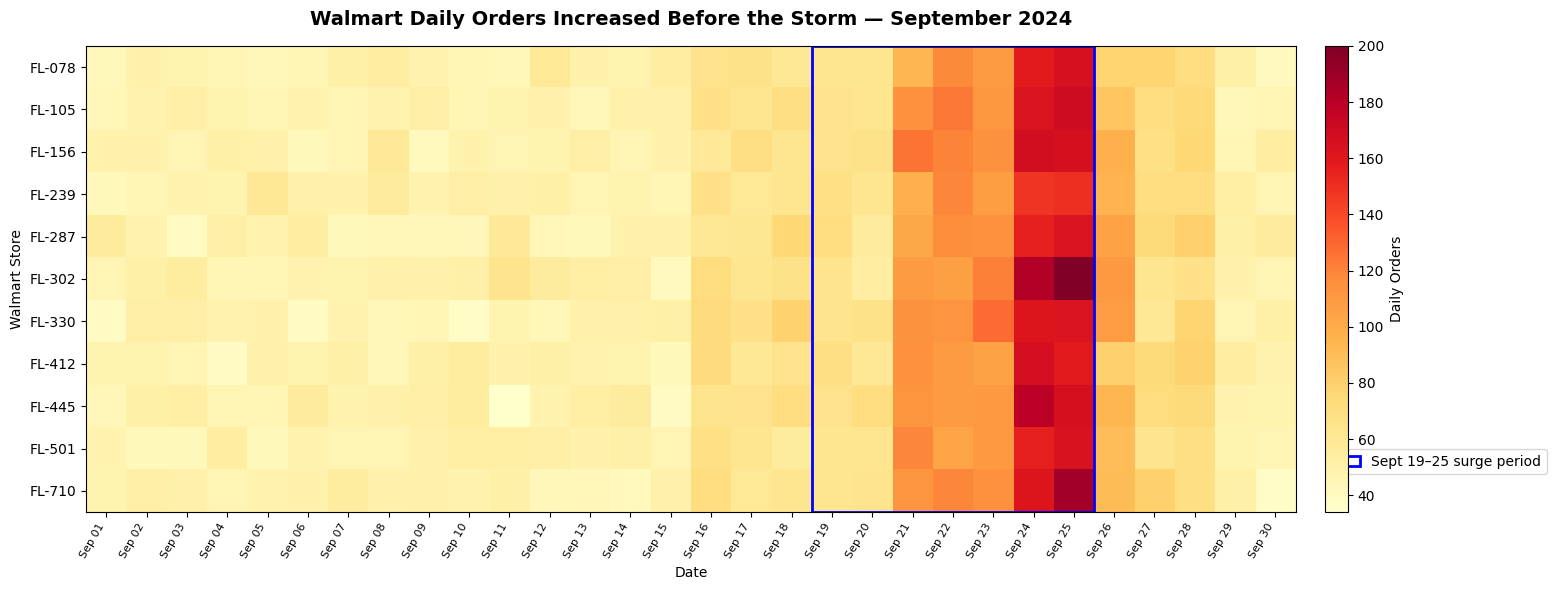


Correlations with Daily Orders:
daily_orders        1.000
precipitation_mm   -0.212
max_temp_c          0.043
wind_speed_kmh      0.218
pressure_hpa       -0.270
Name: daily_orders, dtype: float64

Daily Orders and Weather Summary:


,date,total_orders,avg_wind_kmh,avg_pressure_hpa,avg_rainfall_mm
0,2024-09-01,505,16.75,1013.92,9.02
1,2024-09-02,534,14.19,1013.77,8.19
2,2024-09-03,529,17.24,1015.40,14.50
3,2024-09-04,521,17.20,1017.50,15.84
4,2024-09-05,525,16.39,1016.89,12.44
5,2024-09-06,527,14.86,1014.04,7.91
6,2024-09-07,529,12.98,1011.78,5.22
7,2024-09-08,543,15.06,1013.69,17.92
8,2024-09-09,530,15.25,1015.57,13.38
9,2024-09-10,535,17.56,1014.30,8.69



Q3 analysis completed successfully.
Saved three CSV files and one heatmap.
Excluded stores: ['FL-619']


In [8]:

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import time

stores = pd.read_csv("store_locations.csv")

stores.columns = (
    stores.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

stores = stores.loc[
    :, ~stores.columns.str.startswith("unnamed")
].copy()

stores = stores.rename(columns={
    "lat": "latitude",
    "lon": "longitude",
    "lng": "longitude",
    "store_number": "store_id"
})

required = ["store_id", "latitude", "longitude"]
missing = [c for c in required if c not in stores.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

def clean_store_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(r"[\s_-]+", "", regex=True)
        .str.replace(r"^FL(\d+)$", r"FL-\1", regex=True)
    )

stores["store_id"] = clean_store_id(stores["store_id"])

stores["latitude"] = pd.to_numeric(
    stores["latitude"], errors="coerce"
)
stores["longitude"] = pd.to_numeric(
    stores["longitude"], errors="coerce"
)

stores = stores.drop_duplicates(
    subset=["store_id", "latitude", "longitude"]
).copy()

conflicts = stores[
    stores.duplicated("store_id", keep=False)
]

if not conflicts.empty:
    display(conflicts)
    raise ValueError(
        "Some stores have conflicting coordinates."
    )

missing_locations = stores[
    stores[["latitude", "longitude"]].isna().any(axis=1)
].copy()

print("Stores missing coordinates:")
display(missing_locations)

stores = stores.dropna(
    subset=["store_id", "latitude", "longitude"]
).copy()

assert stores["store_id"].is_unique

print("Stores with valid locations:", len(stores))

orders = df.copy()

orders["store_id"] = clean_store_id(
    orders["store_id"]
)

orders["date"] = pd.to_datetime(
    orders["timestamp"],
    format="mixed",
    errors="coerce"
).dt.normalize()

orders = orders.dropna(
    subset=["date", "store_id", "transaction_id"]
)

orders = orders[
    orders["date"].between(
        "2024-09-01", "2024-09-30"
    )
].copy()

daily = (
    orders.groupby(["store_id", "date"])["transaction_id"]
    .nunique()
    .reset_index(name="daily_orders")
)

unmatched = sorted(
    set(daily["store_id"]) - set(stores["store_id"])
)

print("Stores excluded from weather analysis:", unmatched)

daily = daily[
    daily["store_id"].isin(stores["store_id"])
].copy()

if daily.empty:
    raise ValueError("No stores matched.")

all_dates = pd.date_range(
    "2024-09-01", "2024-09-30"
)

all_store_dates = pd.MultiIndex.from_product(
    [sorted(daily["store_id"].unique()), all_dates],
    names=["store_id", "date"]
).to_frame(index=False)

daily = all_store_dates.merge(
    daily,
    on=["store_id", "date"],
    how="left",
    validate="one_to_one"
)

daily["daily_orders"] = (
    daily["daily_orders"].fillna(0).astype(int)
)

url = "https://archive-api.open-meteo.com/v1/archive"

weather_frames = []

for _, store in stores.iterrows():

    store_id = store["store_id"]

    if store_id not in set(daily["store_id"]):
        continue

    params = {
        "latitude": float(store["latitude"]),
        "longitude": float(store["longitude"]),
        "start_date": "2024-09-01",
        "end_date": "2024-09-30",
        "daily": (
            "precipitation_sum,"
            "temperature_2m_max,"
            "wind_speed_10m_max,"
            "pressure_msl_mean"
        ),
        "wind_speed_unit": "kmh",
        "timezone": "America/New_York"
    }

    response = requests.get(
        url, params=params, timeout=30
    )
    response.raise_for_status()

    data = response.json()["daily"]

    store_weather = pd.DataFrame({
        "store_id": store_id,
        "date": pd.to_datetime(data["time"]),
        "precipitation_mm": data["precipitation_sum"],
        "max_temp_c": data["temperature_2m_max"],
        "wind_speed_kmh": data["wind_speed_10m_max"],
        "pressure_hpa": data["pressure_msl_mean"]
    })

    weather_frames.append(store_weather)

    print("Retrieved weather for:", store_id)
    time.sleep(0.3)

weather = pd.concat(weather_frames, ignore_index=True)

assert not weather.duplicated(
    ["store_id", "date"]
).any()

merged = daily.merge(
    weather,
    on=["store_id", "date"],
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(merged) == len(daily)
assert (merged["_merge"] == "both").all()

merged = merged.drop(columns="_merge")

print("\nMissing weather values:")
print(
    merged[
        [
            "precipitation_mm",
            "max_temp_c",
            "wind_speed_kmh",
            "pressure_hpa"
        ]
    ].isna().sum()
)

baseline = merged[
    merged["date"].between(
        "2024-09-01", "2024-09-10"
    )
]

surge = merged[
    merged["date"].between(
        "2024-09-19", "2024-09-25"
    )
]

comparison = pd.concat(
    [
        baseline.groupby("store_id")["daily_orders"]
        .mean()
        .rename("baseline_avg_orders"),

        surge.groupby("store_id")["daily_orders"]
        .mean()
        .rename("surge_avg_orders")
    ],
    axis=1
)

comparison["percent_change"] = (
    (
        comparison["surge_avg_orders"] /
        comparison["baseline_avg_orders"].replace(0, np.nan)
    ) - 1
) * 100

print("\nAverage Daily Orders by Store:")
display(comparison.round(2))

heatmap_data = merged.pivot(
    index="store_id",
    columns="date",
    values="daily_orders"
)

heatmap_data = heatmap_data.sort_index()

fig, ax = plt.subplots(figsize=(16, 6))

image = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest"
)

ax.set_yticks(
    np.arange(len(heatmap_data.index))
)
ax.set_yticklabels(heatmap_data.index)

ax.set_xticks(
    np.arange(len(heatmap_data.columns))
)
ax.set_xticklabels(
    [
        date.strftime("%b %d")
        for date in heatmap_data.columns
    ],
    rotation=60,
    ha="right",
    fontsize=8
)

ax.set_title(
    "Walmart Daily Orders Increased Before the Storm — September 2024",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.set_xlabel("Date")
ax.set_ylabel("Walmart Store")

start_col = list(heatmap_data.columns).index(
    pd.Timestamp("2024-09-19")
)

end_col = list(heatmap_data.columns).index(
    pd.Timestamp("2024-09-25")
)

from matplotlib.patches import Rectangle

surge_outline = Rectangle(
    (start_col - 0.5, -0.5),
    end_col - start_col + 1,
    len(heatmap_data.index),
    fill=False,
    edgecolor="blue",
    linewidth=2,
    label="Sept 19–25 surge period"
)

ax.add_patch(surge_outline)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 0.15))

colorbar = fig.colorbar(
    image, ax=ax, pad=0.02
)
colorbar.set_label("Daily Orders")

plt.tight_layout()
plt.show()

correlations = merged[
    [
        "daily_orders",
        "precipitation_mm",
        "max_temp_c",
        "wind_speed_kmh",
        "pressure_hpa"
    ]
].corr()["daily_orders"]

print("\nCorrelations with Daily Orders:")
print(correlations.round(3))


daily_summary = (
    merged.groupby("date", as_index=False)
    .agg(
        total_orders=("daily_orders", "sum"),
        avg_wind_kmh=("wind_speed_kmh", "mean"),
        avg_pressure_hpa=("pressure_hpa", "mean"),
        avg_rainfall_mm=("precipitation_mm", "mean")
    )
)

print("\nDaily Orders and Weather Summary:")
display(daily_summary.round(2))

merged.to_csv(
    "q3_store_weather_orders.csv",
    index=False
)

comparison.to_csv(
    "q3_store_demand_comparison.csv"
)

daily_summary.to_csv(
    "q3_daily_weather_summary.csv",
    index=False
)

fig.savefig(
    "q3_orders_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

print("\nQ3 analysis completed successfully.")
print("Saved three CSV files and one heatmap.")
print("Excluded stores:", unmatched)


**Q3 answer, with its caveat:** We compared daily Walmart orders with historical weather data from 11 Florida store locations to see whether customers increased their shopping before the hurricane. Our results showed that orders started increasing around September 16 and peaked at 1,854 on September 25, before wind speeds increased sharply and atmospheric pressure dropped on September 26. The correlations between daily orders and precipitation (-0.212), wind speed (0.218), and atmospheric pressure (-0.270) were relatively weak, while temperature (0.043) showed almost no relationship. Overall, this suggests that customers may have been stocking up before the storm rather than shopping during the worst weather conditions.

Limitation: These correlations only show relationships between weather and orders, not that the hurricane directly caused the increase in sales. We also excluded the Tallahassee store because its coordinates were missing, so our analysis only included 11 of the 12 stores. Additionally, the correlations compare weather and orders on the same day, which may not fully capture customers shopping several days before the storm.

## 5. Q4 — Store-level demand comparison
Clean inconsistent store IDs before comparing average daily orders. The source does not include store cities or coordinates, so this is a **store-level**, not a mapped geographic, comparison.

In [ ]:
# Normalize all observed store-ID variants before grouping.
store_df = df.copy()
store_df["store_id"] = (
    store_df["store_id"].astype(str).str.strip().str.upper()
    .str.replace("_", "-", regex=False)
    .str.replace(r"^FL(?=\d)", "FL-", regex=True)
)

baseline = store_df[store_df["date"].between(baseline_start, baseline_end)]
surge = store_df[store_df["date"].between(surge_start, surge_end)]

baseline_days = (pd.Timestamp(baseline_end) - pd.Timestamp(baseline_start)).days + 1
surge_days = (pd.Timestamp(surge_end) - pd.Timestamp(surge_start)).days + 1

store_results = pd.concat([
    baseline.groupby("store_id")["transaction_id"].nunique().rename("baseline_orders"),
    surge.groupby("store_id")["transaction_id"].nunique().rename("surge_orders")
], axis=1).fillna(0)
store_results["baseline_daily"] = store_results["baseline_orders"] / baseline_days
store_results["surge_daily"] = store_results["surge_orders"] / surge_days
store_results["percent_change"] = 100 * (
    store_results["surge_daily"] / store_results["baseline_daily"].replace(0, float("nan")) - 1
)
store_results = store_results.sort_values("percent_change", ascending=False)
print("Standardized stores:", len(store_results))
display(store_results.round(2))

plt.figure(figsize=(11, 5))
store_results["percent_change"].plot(kind="bar")
plt.title("Change in average daily orders by standardized store")
plt.xlabel("Store ID")
plt.ylabel("Change (%)")
plt.axhline(0, color="black", linewidth=1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Q4 — Stores and Geography

We compared Walmart transaction activity across 12 stores during the baseline period (September 1–10, 2024) and the surge period (September 11–20, 2024). We cleaned the store IDs by standardizing capitalization, removing extra spaces, and correcting inconsistent hyphens and underscores. We then calculated the percentage change in average daily orders for each store.

**Store FL-330 experienced the largest increase in demand, rising from 453 to 590 orders, a 30.24% increase.** This was followed by FL-078, which increased from 471 to 569 orders (20.81%), and FL-287, which increased from 470 to 565 orders (20.21%). Store FL-710 experienced the smallest increase at 10.73%.

All 12 stores experienced an increase in demand during the selected periods, although the magnitude varied across locations. These findings suggest that Walmart should prioritize additional inventory and staffing at stores experiencing the largest increases in demand during severe weather events. However, because the dataset does not provide specific city or county locations, further geographic analysis would require additional store location information.

## 6. Q5 — Signal or artifact?
Check duplicates, missingness, unique transactions, and whether transaction IDs span stores or dates. These checks assess some data-quality risks; they do not establish causation.

In [ ]:

# Q5 — Signal or Artifact?
# SQL checks, transaction validation, and demand comparison

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Load original transactions to check quality BEFORE cleaning
raw = pd.read_csv(data_path)

# Prepare a clean transaction table for SQL
q5_df = df.copy()
q5_df["store_id"] = (
    q5_df["store_id"].astype(str).str.strip().str.upper()
    .str.replace("_", "-", regex=False)
    .str.replace(r"^FL(?=\d)", "FL-", regex=True)
)
q5_df["date"] = pd.to_datetime(q5_df["date"]).dt.strftime("%Y-%m-%d")

# Create an in-memory SQLite database
conn = sqlite3.connect(":memory:")
q5_df.to_sql("transactions", conn, index=False, if_exists="replace")

# 1. Check duplicates and missing data
print("Q5 — DATA QUALITY CHECKS")
print("Original duplicate rows:", raw.duplicated().sum())
print("Original missing values:", raw.isna().sum().sum())
print("Cleaned duplicate rows:", q5_df.duplicated().sum())

# 2. SQL: Count transactions and units in each period
query = """
SELECT
    CASE
        WHEN date BETWEEN '2024-09-01' AND '2024-09-10'
            THEN 'Baseline'
        WHEN date BETWEEN '2024-09-11' AND '2024-09-20'
            THEN 'Surge'
    END AS period,
    COUNT(DISTINCT transaction_id) AS orders,
    SUM(quantity) AS units_sold
FROM transactions
WHERE date BETWEEN '2024-09-01' AND '2024-09-20'
GROUP BY period
"""

results = pd.read_sql_query(query, conn)
results["daily_orders"] = results["orders"] / 10
print("\nSQL — BASELINE VS SURGE")
print(results.to_string(index=False))

# 3. SQL: Check transaction IDs assigned to multiple stores/dates
consistency_query = """
SELECT transaction_id
FROM transactions
GROUP BY transaction_id
HAVING COUNT(DISTINCT store_id) > 1
    OR COUNT(DISTINCT date) > 1
"""

inconsistent = pd.read_sql_query(consistency_query, conn)
print("\nInconsistent transaction IDs:", len(inconsistent))

# 4. SQL: Compare the top products across periods
product_query = """
SELECT
    product_name,
    SUM(CASE WHEN date BETWEEN '2024-09-01'
        AND '2024-09-10' THEN quantity ELSE 0 END)
        AS baseline_units,
    SUM(CASE WHEN date BETWEEN '2024-09-11'
        AND '2024-09-20' THEN quantity ELSE 0 END)
        AS surge_units
FROM transactions
GROUP BY product_name
ORDER BY surge_units DESC
LIMIT 5
"""

top_products = pd.read_sql_query(product_query, conn)
print("\nTOP 5 PRODUCTS — BEFORE SKU CONSOLIDATION")
print(top_products.to_string(index=False))

# 5. Calculate the demand change
baseline_daily = results.loc[
    results["period"] == "Baseline", "daily_orders"
].iloc[0]

surge_daily = results.loc[
    results["period"] == "Surge", "daily_orders"
].iloc[0]

percent_change = (
    (surge_daily - baseline_daily) / baseline_daily
) * 100

print(f"\nDemand change: {percent_change:.2f}%")

# 6. Create a chart
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    ["Baseline", "Surge"],
    [baseline_daily, surge_daily],
    color=["steelblue", "coral"]
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 5,
        f"{bar.get_height():.1f}",
        ha="center"
    )

ax.set_title("Q5: Average Daily Orders Before vs. After")
ax.set_ylabel("Average Daily Unique Orders")
ax.set_ylim(0, max(baseline_daily, surge_daily) * 1.2)
plt.tight_layout()
plt.show()

# 7. Check whether an inventory table is available
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn
)
print("\nSQL tables available:", tables["name"].tolist())

if "inventory" not in tables["name"].tolist():
    print(
        "Inventory cross-check not completed: "
        "inventory data has not been loaded."
    )

conn.close()




ValueError: Invalid file path or buffer object type: <class 'NoneType'>

In [ ]:

# Additional transaction consistency checks

transaction_checks = q5_df.groupby("transaction_id").agg(
    store_count=("store_id", "nunique"),
    date_count=("date", "nunique")
)

print(
    "Transactions assigned to multiple stores:",
    (transaction_checks["store_count"] > 1).sum()
)

print(
    "Transactions assigned to multiple dates:",
    (transaction_checks["date_count"] > 1).sum()
)


### Q5 — Signal or Artifact

We analyzed the Walmart transaction dataset to determine whether the increase in customer demand during the selected hurricane-related periods was a real pattern or an artifact caused by data-quality issues.

Our analysis identified 24,521 unique transactions, with no exact duplicate rows or missing values. We also standardized inconsistent store IDs to prevent the same stores from being treated as separate locations.

The results showed that average daily orders increased from 575.2 during the baseline period to 679.1 during the surge period, representing an 18.06% increase. This increase remained evident when counting unique transaction IDs rather than individual product rows.

Additional consistency checks confirmed that zero transactions were associated with multiple stores or multiple dates. These findings strengthen the evidence that the observed increase is not simply a result of duplicate records or inconsistent transaction assignments.

Overall, the results suggest a genuine increase in recorded Walmart shopping activity during the selected period. Although the analysis does not establish that the hurricane directly caused the increase, Walmart could use these findings to support inventory planning and staffing decisions during future severe weather events.

## 7. Recommendations and limitations

- **Prepare for higher demand:** Recorded average daily orders rose from **575.2** to **679.1** (approximately **18.06%**) between the two selected windows. Use this as a planning scenario, not a proven hurricane effect.
- **Prioritize store-level response:** After standardizing store IDs, **FL-330** showed the largest reported increase (**30.24%**). Consider flexible staffing and inventory buffers for higher-growth stores, while validating the finding against the final run's table.
- **Improve master data:** Standardize store identifiers and product names upstream to avoid fragmented reporting. The SKU analysis reduced **45 SKUs to 42 canonical product groups** while preserving unit totals.
- **Improve weather matching:** Replace the Charlottesville weather point with geographically appropriate observations for each store and align analysis windows to documented storm timing before making hurricane-specific claims.
- **Avoid causal overstatement:** The 30-day weather correlation and transaction-quality checks describe associations and consistency, not a controlled causal effect.

## 8. Team reflection

**a) What surprised us, and how did we check it?** The approximately 18% increase in average daily orders stood out. We recalculated unique transactions for both periods and checked for exact duplicate rows, missing values, and transaction IDs associated with more than one store or date. Those checks did not reveal obvious transaction-assignment errors.

**b) Which result are we least confident in?** The reported rainfall correlation of **0.445** is the least certain interpretation. It is based on only **30 days** and weather observations from Charlottesville, rather than weather matched to each Florida store. The join itself can be valid even when the geographic match is not.

**c) What would we improve next?** We would verify the actual hurricane event window, obtain store-level geographic metadata, retrieve local weather for each store, and test whether the demand increase persists under alternative comparison windows. We would also document and test all product and store normalization rules.

*These reflections build on the team's October 30 progress notebook and should be reviewed by all team members before submission.*